# Drug-class classification from CARD protein features

This notebook follows the training → evaluation → saved model → unseen-sequence prediction → SHAP workflow in `family_classifier_importance_3.ipynb`. It trains **drug-class predictors only**, using Pfeature and ProFET descriptors already calculated for CARD homolog-model proteins.

A protein can have several CARD drug-class annotations. Each ARO is represented once, with a multi-hot target vector; a prediction may contain zero, one, or several supported classes. The `family` column in the drug-class feature CSVs is a file-group label, **not an ARG-family input feature**. The classifier predicts CARD annotation membership, not a clinical susceptibility measurement.

**Run order:** configuration and data checks; grouped cross-validation and held-out SHAP; metrics and figures; final refit and one saved model archive; standalone unseen-sequence prediction; comparison exports. All cells are supplied unexecuted. Training and output creation happen only when you run them.

The inspected inputs contain 6,059 AROs and 39 represented classes. Counts are recalculated when run. The default minimum of 10 positives follows the earlier notebook; rare or unsplittable classes are listed explicitly and are not silently treated as modelled classes. All proteins remain available as background examples for supported labels.

**Single saved model:** `drug_class_classifier.zip` contains the native LightGBM predictors, feature schema, label order, thresholds and provenance. Internally it has one binary predictor per supported label, exposed through one load/predict interface. A mutually exclusive softmax classifier would discard valid drug-class memberships.


In [19]:
from pathlib import Path

PROJECT_ROOT = Path("/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family")
CARD_ROOT = PROJECT_ROOT / "CARD_DATA" / "card-data"
FINAL_RESULTS = CARD_ROOT / "refined_details" / "Final_Results"

PFEATURE_CSV = FINAL_RESULTS / "Drug_Class_Fastas_pfeatures" / "all_families_features.csv"
PROFET_CSV = FINAL_RESULTS / "Drug_Class_Fastas_profet" / "all_families_profet_features.csv"
ARO_INDEX_TSV = CARD_ROOT / "refined_details" / "aro_index.tsv"
PROTEIN_FASTA = CARD_ROOT / "protein_fasta_protein_homolog_model.fasta"
OUTPUT_DIR = FINAL_RESULTS / "ML_on_Drug_Class" / "results" / "drug_class_classifiers"
MODEL_PATH = OUTPUT_DIR / "models" / "drug_class_classifier.zip"

# Optional stronger grouping: CSV with aro_accession, cluster_id, one row per ARO.
# Generate it externally from protein-sequence clustering with documented identity/coverage.
SEQUENCE_CLUSTER_CSV = None
# Used only if no sequence-cluster CSV is supplied. Matches the earlier notebook's proxy.
CV_GROUP_RADIUS = 1.0
MIN_CLASS_N = 10
N_FOLDS = 5
RANDOM_SEED = 0

# Observed to vary across copies of the same protein in these source tables.
# Drop them for EVERY class, both in training and prediction.
EXCLUDE_FEATURE_PREFIXES = ("PRI_", "RRI_")
PREDICTION_THRESHOLD = 0.5
TOP_N_FEATURES = 15
SHAP_SAFETY_THRESHOLD = 2.0
SHAP_BATCH_SIZE = 256

# CPU default; no automatic installation or hardware-dependent parameter changes.
LGB_PARAMS = dict(
    objective="binary", n_estimators=300, num_leaves=15,
    learning_rate=0.05, min_child_samples=10, reg_lambda=1.0,
    is_unbalance=True, verbosity=-1, n_jobs=2,
    deterministic=True, force_col_wise=True,
)

# Optional comparison only; this notebook does not retrain ARG-family models.
FAMILY_SHAP_CSV = (
    FINAL_RESULTS / "ML_on_Drug_Class" / "results" / "family_classifiers"
    / "top_features_shap.csv"
)
# A complete family × feature table can replace the top-15 file above.


In [2]:
import csv
import hashlib
import json
import math
import re
import textwrap
import zipfile
from collections import defaultdict
from datetime import datetime, timezone
from importlib.metadata import version

import numpy as np
import pandas as pd
import lightgbm as lgb
import shap
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import radius_neighbors_graph
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    hamming_loss, precision_score, recall_score, roc_auc_score, roc_curve,
    precision_recall_curve,
)

PACKAGE_VERSIONS = {
    name: version(name)
    for name in ("numpy", "pandas", "scikit-learn", "lightgbm", "shap", "matplotlib")
}
print(PACKAGE_VERSIONS)
# The existing jupyter environment has these dependencies; no pip-install cells are run here.


/home/user/miniforge3/envs/jupyter/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'numpy': '2.4.4', 'pandas': '2.3.3', 'scikit-learn': '1.8.0', 'lightgbm': '4.7.0', 'shap': '0.52.0', 'matplotlib': '3.10.8'}


## 1. Load, reconcile and deduplicate the feature tables

Merge Pfeature and ProFET on the existing `(drug_class, sequence_id)` keys with one-to-one validation. Recover the ARO accession from each sequence ID and match its drug-class labels directly to `aro_index.tsv`.

Check that repeated AROs have identical retained numeric features before collapsing their copied rows. `PRI_*` and `RRI_*` are excluded by the fixed configuration because the current extracts contain class-file-dependent differences in those columns. Any other disagreement stops the workflow. Feature names retain their original spelling so later family/drug-class comparisons can join on them.

LightGBM receives native missing values. There is no global imputation or label-conditioned cleaning in the model inputs. Missing columns and failed feature-table joins cause explicit errors. Constant columns are retained in the schema and can receive zero importance.


In [3]:
def canonical_aro(value):
    value = str(value).strip()
    hits = set(re.findall(r"ARO:(\d+)", value))
    if not hits:
        match = re.fullmatch(r"(?:f\d+_)+(\d+)", value)
        if match:
            hits = {match.group(1)}
    if not hits and value.isdigit():
        hits = {value}
    if len(hits) != 1:
        raise ValueError(f"Cannot resolve exactly one ARO accession from {value!r}")
    return "ARO:" + next(iter(hits))


def class_file_label(label):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", label.strip()).strip("._")


def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def read_drug_feature_table(path):
    with Path(path).open(newline="", encoding="utf-8-sig") as handle:
        columns = next(csv.reader(handle))
    if len(columns) != len(set(columns)):
        raise ValueError(f"Duplicate column names in {path}")
    frame = pd.read_csv(path, dtype={"sequence_id": str}, keep_default_na=True)
    label_columns = [c for c in ("drug_class", "Drug Class", "family") if c in frame]
    if len(label_columns) != 1 or "sequence_id" not in frame:
        raise ValueError(f"{path}: expected sequence_id and exactly one class-label column")
    frame = frame.rename(columns={label_columns[0]: "drug_class"})
    if frame[["drug_class", "sequence_id"]].isna().any().any():
        raise ValueError(f"Missing IDs/labels in {path}")
    for column in ("drug_class", "sequence_id"):
        frame[column] = frame[column].astype(str).str.strip()
        if frame[column].eq("").any():
            raise ValueError(f"Blank {column} in {path}")
    if frame.duplicated(["drug_class", "sequence_id"]).any():
        raise ValueError(f"Duplicate (class, sequence_id) keys in {path}; check repeated master-file merges")
    return frame


def read_card_drug_lookup(path):
    table = pd.read_csv(path, sep="\t", dtype=str, keep_default_na=False)
    required = {"ARO Accession", "Drug Class"}
    if not required.issubset(table.columns):
        raise ValueError(f"CARD index needs {sorted(required)}")
    lookup = defaultdict(set)
    for aro, labels in table[["ARO Accession", "Drug Class"]].itertuples(index=False, name=None):
        lookup[canonical_aro(aro)].update(x.strip() for x in labels.split(";") if x.strip())
    labels = sorted({label for values in lookup.values() for label in values})
    reverse = {}
    for label in labels:
        slug = class_file_label(label)
        if slug in reverse and reverse[slug] != label:
            raise ValueError(f"Drug-class filename collision: {label!r} and {reverse[slug]!r}")
        reverse[slug] = label
    return dict(lookup), reverse


def protein_hashes_by_aro(path):
    hashes = {}
    header, parts = None, []

    def store_record(h, sequence):
        aro = canonical_aro(h)
        if not sequence:
            raise ValueError(f"Empty sequence for {aro}")
        digest = hashlib.sha256(sequence.upper().encode()).hexdigest()
        if aro in hashes and hashes[aro] != digest:
            raise ValueError(f"Multiple different protein sequences for {aro}")
        hashes[aro] = digest

    with Path(path).open(encoding="utf-8") as handle:
        for line in handle:
            if line.startswith(">"):
                if header is not None:
                    store_record(header, "".join(parts))
                header, parts = line[1:].strip(), []
            elif line.strip():
                if header is None:
                    raise ValueError("Protein FASTA contains sequence before its first header")
                parts.append(line.strip())
    if header is not None:
        store_record(header, "".join(parts))
    return hashes


def load_drug_training_data(pfeature_csv, profet_csv, aro_tsv, protein_fasta, excluded_prefixes):
    pf = read_drug_feature_table(pfeature_csv)
    pr = read_drug_feature_table(profet_csv)
    keys = ["drug_class", "sequence_id"]
    pf_features = [c for c in pf.columns if c not in keys]
    pr_features = [c for c in pr.columns if c not in keys]
    collisions = set(pf_features) & set(pr_features)
    if collisions:
        raise ValueError(f"Descriptor names occur in both extractors: {sorted(collisions)}")

    merged = pf.merge(pr, on=keys, how="outer", validate="one_to_one", indicator=True)
    if not merged["_merge"].eq("both").all():
        raise ValueError(f"Unmatched extraction rows: {merged['_merge'].value_counts().to_dict()}")
    merged = merged.drop(columns="_merge")
    merged["aro_accession"] = merged["sequence_id"].map(canonical_aro)
    lookup, reverse_labels = read_card_drug_lookup(aro_tsv)
    missing_aros = sorted(set(merged["aro_accession"]) - set(lookup))
    if missing_aros:
        raise ValueError(f"ARO accessions absent from CARD: {missing_aros[:10]}")

    def resolve_label(label):
        if label in reverse_labels.values():
            return label
        if label not in reverse_labels:
            raise ValueError(f"Unknown drug-class file label: {label}")
        return reverse_labels[label]

    merged["drug_class"] = merged["drug_class"].map(resolve_label)
    observed = merged.groupby("aro_accession")["drug_class"].agg(set)
    mismatched = [aro for aro, labels in observed.items() if labels != lookup[aro]]
    if mismatched:
        raise ValueError(f"Drug-class copies do not match CARD annotations: {mismatched[:10]}")

    raw_features = pf_features + pr_features
    excluded = [c for c in raw_features if c.startswith(tuple(excluded_prefixes))]
    features = [c for c in raw_features if c not in excluded]
    if not features:
        raise ValueError("No retained descriptors")
    numeric = merged[features].apply(pd.to_numeric, errors="raise").astype(float)
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    unique_counts = numeric.groupby(merged["aro_accession"]).nunique(dropna=False)
    inconsistent = unique_counts.columns[unique_counts.gt(1).any()].tolist()
    if inconsistent:
        raise ValueError(f"Same-ARO descriptor conflicts; correct the extracts first: {inconsistent[:20]}")
    keep = ~merged["aro_accession"].duplicated()
    meta = merged.loc[keep, ["aro_accession", "sequence_id"]].reset_index(drop=True)
    X_df = numeric.loc[keep].reset_index(drop=True)
    if X_df.isna().all(axis=1).any():
        raise ValueError("At least one protein has no usable numeric descriptors")
    hashes = protein_hashes_by_aro(protein_fasta)
    meta["sequence_sha256"] = meta["aro_accession"].map(hashes)
    if meta["sequence_sha256"].isna().any():
        raise ValueError("Some feature AROs are absent from the protein FASTA")
    label_sets = [lookup[aro] for aro in meta["aro_accession"]]
    labels = sorted(set().union(*label_sets))
    Y = np.array([[label in memberships for label in labels] for memberships in label_sets], dtype=np.uint8)
    feature_sources = {c: "Pfeature" if c in pf_features else "ProFET" for c in features}
    audit = {
        "input_assignment_rows": len(merged), "unique_aro_records": len(meta),
        "represented_drug_classes": len(labels),
        "multi_label_proteins": int((Y.sum(axis=1) > 1).sum()),
        "retained_features": len(features), "excluded_features": excluded,
        "missing_numeric_values": int(X_df.isna().sum().sum()),
    }
    return meta, X_df, labels, Y, feature_sources, audit


In [4]:
meta, X_df, all_labels, Y_all, feature_sources, data_audit = load_drug_training_data(
    PFEATURE_CSV, PROFET_CSV, ARO_INDEX_TSV, PROTEIN_FASTA, EXCLUDE_FEATURE_PREFIXES
)
print(json.dumps(data_audit, indent=2))
display(meta.head())
display(pd.DataFrame({"drug_class": all_labels, "n_positive": Y_all.sum(axis=0)}).sort_values("n_positive"))


{
  "input_assignment_rows": 12913,
  "unique_aro_records": 6059,
  "represented_drug_classes": 39,
  "multi_label_proteins": 3951,
  "retained_features": 996,
  "excluded_features": [
    "RRI_A",
    "RRI_C",
    "RRI_D",
    "RRI_E",
    "RRI_F",
    "RRI_G",
    "RRI_H",
    "RRI_I",
    "RRI_K",
    "RRI_L",
    "RRI_M",
    "RRI_N",
    "RRI_P",
    "RRI_Q",
    "RRI_R",
    "RRI_S",
    "RRI_T",
    "RRI_V",
    "RRI_W",
    "RRI_Y",
    "PRI_PC",
    "PRI_NC",
    "PRI_NE",
    "PRI_PO",
    "PRI_NP",
    "PRI_AL",
    "PRI_CY",
    "PRI_AR",
    "PRI_AC",
    "PRI_BS",
    "PRI_NE_pH",
    "PRI_HB",
    "PRI_HL",
    "PRI_NT",
    "PRI_HX",
    "PRI_SC",
    "PRI_SS_HE",
    "PRI_SS_ST",
    "PRI_SS_CO",
    "PRI_SA_BU",
    "PRI_SA_EX",
    "PRI_SA_IN",
    "PRI_TN",
    "PRI_SM"
  ],
  "missing_numeric_values": 33
}


,aro_accession,sequence_id,sequence_sha256
0,ARO:3000237,ARO:3000237|gb|ACN32294.1|ARO:3000237|TolC,fe21d1df428886620dc8e008ce9c64d889286df988a8c7...
1,ARO:3000377,ARO:3000377|gb|AAG03814.1|ARO:3000377|MexA,9686c53af99c2a7f17eddc51e8d512cddc54b0839b2873...
2,ARO:3000378,ARO:3000378|gb|AAA74437.1|ARO:3000378|MexB,82a4a19357be028d5e2b80f8fbfa98dec2dbe1c2d5c81c...
3,ARO:3000379,ARO:3000379|gb|AAG03816.1|ARO:3000379|OprM,5a633aa6b36dcabe1d341abe0278cb446620d1d76cbccb...
4,ARO:3000768,ARO:3000768|gb|ACJ59254.1|ARO:3000768|abeS,756e6577ff7a1d447c332ed74e8046b963d306a0cc69b5...


,drug_class,n_positive
5,bicyclomycin-like antibiotic,1
10,elfamycin antibiotic,1
27,orthosomycin antibiotic,1
17,lasso peptide antibiotics,1
16,isoniazid-like antibiotic,2
23,nitrofuran antibiotic,2
2,antibacterial free fatty acids,2
3,antibiotic without defined classification,2
20,moenomycin antibiotic,2
34,ribosomally synthesized and post-translational...,2


## 2. Shared grouped cross-validation

Every class uses the **same held-out folds**, so aggregate multi-label metrics describe predictions for the same unseen proteins.

If `SEQUENCE_CLUSTER_CSV` is provided, its externally determined sequence clusters define groups. Otherwise use the earlier notebook's radius-1.0 standardized-feature graph as an **approximate descriptor-similarity grouping**, with exact sequence copies linked as well. That fallback does not establish generalization to distant homologues. Scaling/imputation below are used only to define this grouping; these transformed values never enter the classifiers.

The split stratifier uses each protein's rarest eligible annotation as a single balancing key (or a background key). This is a heuristic for multi-label balance. Inspect each class in every fold; require both positives and negatives in training and validation. Try fewer folds if needed for coverage, using labels/group counts only, never model scores. If no split supports every eligible class, report unsupported classes and exclude their predictors. Do not loosen grouping merely to improve scores.

At least 10 positive **AROs** is the default sample filter, and at least two independent positive and negative groups are also required. These checks do not make rare-class estimates precise.


In [5]:
def build_cv_groups(X_df, meta, cluster_csv=None, radius=1.0):
    n = len(meta)
    row_links, col_links = [], []
    if cluster_csv is not None:
        clusters = pd.read_csv(cluster_csv, dtype=str, keep_default_na=False)
        if not {"aro_accession", "cluster_id"}.issubset(clusters.columns):
            raise ValueError("Sequence cluster CSV needs aro_accession, cluster_id")
        clusters["aro_accession"] = clusters["aro_accession"].map(canonical_aro)
        if clusters["aro_accession"].duplicated().any() or clusters["cluster_id"].str.strip().eq("").any():
            raise ValueError("Duplicate AROs or blank cluster identifiers")
        mapped = meta["aro_accession"].map(clusters.set_index("aro_accession")["cluster_id"])
        if mapped.isna().any():
            raise ValueError("Sequence cluster CSV does not cover every feature ARO")
        base_groups = mapped.to_numpy()
        graph = coo_matrix((n, n), dtype=np.uint8).tocsr()
        source = "external_sequence_clusters"
    else:
        if radius <= 0:
            raise ValueError("CV_GROUP_RADIUS must be positive")
        grouping_only = X_df.fillna(X_df.median()).fillna(0.0)
        grouping_scaled = StandardScaler().fit_transform(grouping_only)
        graph = radius_neighbors_graph(
            grouping_scaled, radius=radius, mode="connectivity",
            include_self=True, n_jobs=2,
        )
        base_groups = np.arange(n)
        source = "approximate_descriptor_radius"

    for group_values in (base_groups, meta["sequence_sha256"].to_numpy()):
        first = {}
        for index, value in enumerate(group_values):
            if value in first:
                row_links.append(first[value])
                col_links.append(index)
            else:
                first[value] = index
    if row_links:
        links = coo_matrix((np.ones(len(row_links)), (row_links, col_links)), shape=(n, n))
        graph = graph + links + links.T
    _, groups = connected_components(graph, directed=False)
    return groups, source


def choose_shared_folds(Y, groups, max_folds, seed):
    if Y.shape[1] == 0:
        raise ValueError("No classes satisfy the sample/group support requirements")
    support = Y.sum(axis=0)
    anchor = np.where(Y != 0, support[None, :], np.inf).argmin(axis=1)
    anchor[Y.sum(axis=1) == 0] = Y.shape[1]
    best = None
    upper = min(max_folds, len(np.unique(groups)))
    for n_splits in range(upper, 1, -1):
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        folds = list(splitter.split(np.zeros((len(Y), 1)), anchor, groups))
        valid = np.ones(Y.shape[1], dtype=bool)
        for train, test in folds:
            if set(groups[train]) & set(groups[test]):
                raise AssertionError("CV group leakage")
            for indices in (train, test):
                positives = Y[indices].sum(axis=0)
                valid &= (positives > 0) & (positives < len(indices))
        if best is None or valid.sum() > best[1].sum():
            best = (folds, valid)
        if valid.all():
            return folds, valid
    if best is None or not best[1].any():
        raise ValueError("No class supports a two-sided grouped validation split")
    return best


In [6]:
if MIN_CLASS_N < 2 or N_FOLDS < 2:
    raise ValueError("MIN_CLASS_N and N_FOLDS must be at least 2")
if not 0 < PREDICTION_THRESHOLD < 1 or SHAP_SAFETY_THRESHOLD < 0 or TOP_N_FEATURES < 1:
    raise ValueError("Invalid prediction/SHAP thresholds or TOP_N_FEATURES")

cv_groups, grouping_source = build_cv_groups(X_df, meta, SEQUENCE_CLUSTER_CSV, CV_GROUP_RADIUS)
support_rows = []
for j, label in enumerate(all_labels):
    target = Y_all[:, j]
    n_pos = int(target.sum())
    n_neg = len(target) - n_pos
    positive_groups = len(np.unique(cv_groups[target == 1]))
    negative_groups = len(np.unique(cv_groups[target == 0]))
    reason = ""
    if n_pos < MIN_CLASS_N or n_neg < MIN_CLASS_N:
        reason = "below_minimum_positive_or_negative_records"
    elif min(positive_groups, negative_groups) < 2:
        reason = "fewer_than_two_positive_or_negative_groups"
    support_rows.append({
        "drug_class": label, "n_positive": n_pos, "n_negative": n_neg,
        "positive_groups": positive_groups, "negative_groups": negative_groups,
        "exclusion_reason": reason,
    })
class_support = pd.DataFrame(support_rows)
candidate_idx = np.flatnonzero(class_support["exclusion_reason"].eq("").to_numpy())
folds, fold_eligible = choose_shared_folds(Y_all[:, candidate_idx], cv_groups, N_FOLDS, RANDOM_SEED)
for j in candidate_idx[~fold_eligible]:
    class_support.loc[j, "exclusion_reason"] = "missing_positive_or_negative_examples_in_a_fold"
selected_idx = candidate_idx[fold_eligible]
labels = [all_labels[j] for j in selected_idx]
Y = Y_all[:, selected_idx]
X = X_df.to_numpy(dtype=float)
feature_names = X_df.columns.tolist()
class_support["modelled"] = class_support["drug_class"].isin(labels)
fold_id = np.full(len(meta), -1, dtype=int)
fold_audit_rows = []
for fold_no, (train, test) in enumerate(folds, 1):
    if (fold_id[test] != -1).any():
        raise AssertionError("Overlapping validation rows")
    fold_id[test] = fold_no
    for j, label in enumerate(labels):
        fold_audit_rows.append({
            "fold": fold_no, "drug_class": label,
            "train_positive": int(Y[train, j].sum()), "train_negative": int(len(train) - Y[train, j].sum()),
            "test_positive": int(Y[test, j].sum()), "test_negative": int(len(test) - Y[test, j].sum()),
        })
if (fold_id < 0).any():
    raise AssertionError("Incomplete OOF coverage")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
class_support.to_csv(OUTPUT_DIR / "drug_class_support_and_exclusions.csv", index=False)
pd.DataFrame(fold_audit_rows).to_csv(OUTPUT_DIR / "fold_class_support.csv", index=False)
meta.assign(cv_group=cv_groups, fold=fold_id).to_csv(OUTPUT_DIR / "sequence_fold_manifest.csv", index=False)
(OUTPUT_DIR / "data_audit.json").write_text(json.dumps(data_audit, indent=2))
print(f"{len(meta)} AROs; {len(np.unique(cv_groups))} groups ({grouping_source}); {len(folds)} folds")
print(f"{len(labels)} modelled drug classes / {len(all_labels)} represented; {len(feature_names)} features")
display(class_support)


6059 AROs; 6045 groups (approximate_descriptor_radius); 5 folds
27 modelled drug classes / 39 represented; 996 features


,drug_class,n_positive,n_negative,positive_groups,negative_groups,exclusion_reason,modelled
0,aminocoumarin antibiotic,20,6039,20,6025,,True
1,aminoglycoside antibiotic,239,5820,239,5806,,True
2,antibacterial free fatty acids,2,6057,2,6043,below_minimum_positive_or_negative_records,False
3,antibiotic without defined classification,2,6057,2,6043,below_minimum_positive_or_negative_records,False
4,azole antibiotic,267,5792,267,5778,,True
5,bicyclomycin-like antibiotic,1,6058,1,6044,below_minimum_positive_or_negative_records,False
6,carbapenem,2561,3498,2556,3490,,True
7,cephalosporin,3392,2667,3380,2665,,True
8,diaminopyrimidine antibiotic,81,5978,81,5964,,True
9,disinfecting agents and antiseptics,62,5997,62,5983,,True


## 3. Train and evaluate drug-class predictors

Train an independent binary LightGBM predictor for each supported class on each shared training fold. Record scores only for the held-out fold. Missing descriptors remain NaN, which LightGBM handles natively. The fixed hyperparameters and 0.5 threshold are not selected using these held-out scores.

`is_unbalance=True` follows the earlier binary workflow. Its outputs are model scores on a probability scale and should not be interpreted as calibrated confidence. ROC-AUC and average precision assess ranking; precision, recall and F1 assess the configured threshold.

SHAP explains the held-out predictions in **raw-margin (log-odds) units**, using tree-path-dependent reference counts from each training model. Each explanation is checked against that model's raw output. Accumulate all held-out rows, weighted by their actual row counts; do not average differently sized folds equally. SHAP is a model attribution, not a causal or resistance-mechanism test.

The SHAP rankings describe the cross-validated modelling procedure. The later full-data refit uses the same design, but these tables are not falsely labelled as explanations of that exact refitted object.


In [7]:
def checked_binary_shap(explainer, model, batch):
    explanation = explainer(batch, check_additivity=True)
    if explanation.values.ndim == 3:
        if explanation.values.shape[-1] != 2:
            raise ValueError(f"Unexpected SHAP output shape: {explanation.values.shape}")
        explanation = explanation[..., 1]
    values = np.asarray(explanation.values)
    if values.shape != batch.shape or not np.isfinite(values).all():
        raise ValueError("Non-finite or incorrectly shaped SHAP values")
    base = np.asarray(explanation.base_values)
    if base.ndim == 2 and base.shape[1] == 1:
        base = base[:, 0]
    reconstructed = base + values.sum(axis=1)
    expected = model.booster_.predict(batch, raw_score=True)
    np.testing.assert_allclose(reconstructed, expected, rtol=1e-5, atol=1e-5)
    return values, float(np.max(np.abs(reconstructed - expected)))


def fit_grouped_drug_models(X, Y, labels, features, folds, model_params, seed, batch_size):
    n_rows, n_features = X.shape
    oof = np.full(Y.shape, np.nan, dtype=float)
    shap_abs_sum = np.zeros((len(labels), n_features))
    shap_signed_sum = np.zeros_like(shap_abs_sum)
    shap_max_abs = np.zeros_like(shap_abs_sum)
    explained_rows = np.zeros(len(labels), dtype=int)
    fold_scores, fold_shap = [], []

    for fold_no, (train, test) in enumerate(folds, 1):
        for j, label in enumerate(labels):
            if len(np.unique(Y[train, j])) != 2 or len(np.unique(Y[test, j])) != 2:
                raise ValueError(f"Both target states required: fold={fold_no}, class={label}")
            model = lgb.LGBMClassifier(random_state=seed, **model_params)
            model.fit(X[train], Y[train, j])
            prediction = model.predict_proba(X[test])[:, 1]
            if not np.isfinite(prediction).all():
                raise ValueError(f"Non-finite predictions for {label}")
            oof[test, j] = prediction
            explainer = shap.TreeExplainer(
                model, model_output="raw",
                feature_perturbation="tree_path_dependent", feature_names=features,
            )
            fold_abs_sum = np.zeros(n_features)
            max_additivity_error = 0.0
            for start in range(0, len(test), batch_size):
                batch_indices = test[start:start + batch_size]
                values, error = checked_binary_shap(explainer, model, X[batch_indices])
                fold_abs_sum += np.abs(values).sum(axis=0)
                shap_signed_sum[j] += values.sum(axis=0)
                shap_max_abs[j] = np.maximum(shap_max_abs[j], np.abs(values).max(axis=0))
                max_additivity_error = max(max_additivity_error, error)
            shap_abs_sum[j] += fold_abs_sum
            explained_rows[j] += len(test)
            fold_shap.append(pd.DataFrame({
                "fold": fold_no, "drug_class": label, "feature": features,
                "mean_abs_shap": fold_abs_sum / len(test), "n_explained": len(test),
            }))
            fold_scores.append({
                "fold": fold_no, "drug_class": label,
                "roc_auc": roc_auc_score(Y[test, j], prediction),
                "average_precision": average_precision_score(Y[test, j], prediction),
                "n_validation": len(test), "n_positive": int(Y[test, j].sum()),
                "max_shap_additivity_error": max_additivity_error,
            })
            print(f"Fold {fold_no}/{len(folds)} | {j + 1}/{len(labels)} | {label}", flush=True)
    if not np.isfinite(oof).all() or not np.all(explained_rows == n_rows):
        raise AssertionError("Incomplete out-of-fold predictions or explanations")
    return {
        "oof_scores": oof,
        "mean_abs_shap": shap_abs_sum / explained_rows[:, None],
        "mean_signed_shap": shap_signed_sum / explained_rows[:, None],
        "max_abs_shap": shap_max_abs,
        "fold_scores": pd.DataFrame(fold_scores),
        "fold_shap": pd.concat(fold_shap, ignore_index=True),
    }


In [8]:
# Long-running cell: train the CV models and compute held-out SHAP.
cv_result = fit_grouped_drug_models(
    X, Y, labels, feature_names, folds, LGB_PARAMS, RANDOM_SEED, SHAP_BATCH_SIZE
)
cv_result["fold_scores"].to_csv(OUTPUT_DIR / "fold_model_metrics.csv", index=False)
cv_result["fold_shap"].to_csv(OUTPUT_DIR / "fold_shap_importance.csv", index=False)
np.savez_compressed(
    OUTPUT_DIR / "drug_class_oof_cache.npz",
    scores=cv_result["oof_scores"], y_true=Y, labels=np.asarray(labels, dtype=str),
    aro_accession=meta["aro_accession"].to_numpy(dtype=str), fold=fold_id,
    threshold=np.array(PREDICTION_THRESHOLD),
)
np.savez_compressed(
    OUTPUT_DIR / "drug_class_shap_cache.npz",
    mean_abs=cv_result["mean_abs_shap"], mean_signed=cv_result["mean_signed_shap"],
    max_abs=cv_result["max_abs_shap"], labels=np.asarray(labels, dtype=str),
    feature_names=np.asarray(feature_names, dtype=str),
    feature_source=np.asarray([feature_sources[c] for c in feature_names], dtype=str),
    n_explained=np.array(len(meta)),
)
print("Saved OOF scores and SHAP summaries; figures and tables can be regenerated without retraining.")


Fold 1/5 | 1/27 | aminocoumarin antibiotic
Fold 1/5 | 2/27 | aminoglycoside antibiotic
Fold 1/5 | 3/27 | azole antibiotic
Fold 1/5 | 4/27 | carbapenem
Fold 1/5 | 5/27 | cephalosporin
Fold 1/5 | 6/27 | diaminopyrimidine antibiotic
Fold 1/5 | 7/27 | disinfecting agents and antiseptics
Fold 1/5 | 8/27 | fluoroquinolone antibiotic
Fold 1/5 | 9/27 | glycopeptide antibiotic
Fold 1/5 | 10/27 | glycylcycline
Fold 1/5 | 11/27 | imidazole antibiotic
Fold 1/5 | 12/27 | lincosamide antibiotic
Fold 1/5 | 13/27 | macrolide antibiotic
Fold 1/5 | 14/27 | monobactam
Fold 1/5 | 15/27 | nitroimidazole antibiotic
Fold 1/5 | 16/27 | nonribosomal peptide antibiotics
Fold 1/5 | 17/27 | nucleoside antibiotic
Fold 1/5 | 18/27 | oxazolidinone antibiotic
Fold 1/5 | 19/27 | penicillin beta-lactam
Fold 1/5 | 20/27 | peptide antibiotic
Fold 1/5 | 21/27 | phenicol antibiotic
Fold 1/5 | 22/27 | phosphonic acid antibiotic
Fold 1/5 | 23/27 | pleuromutilin antibiotic
Fold 1/5 | 24/27 | rifamycin antibiotic
Fold 1/5 | 25

## 4. Metrics, confusion matrices, ROC and precision–recall curves

Use cached held-out predictions only. The per-class table contains positive support, negative support, prevalence/AP baseline, AUROC, AP, precision, recall, F1 and raw TN/FP/FN/TP counts. Aggregate results include macro/micro F1, macro/micro AP and AUROC, Hamming loss and exact-match accuracy over **modelled classes only**.

For multi-label classification the appropriate confusion matrices are one 2×2 matrix per drug class. A mutually exclusive drug-class confusion matrix would misrepresent proteins that have more than one true label. Excluded labels are recorded separately. Plots have dynamic labels/counts and are saved as PNG and PDF.


In [9]:
# Can be rerun using only configuration, imports and the cache from a completed CV run.
with np.load(OUTPUT_DIR / "drug_class_oof_cache.npz", allow_pickle=False) as cache:
    eval_scores = cache["scores"]
    eval_y = cache["y_true"]
    eval_labels = cache["labels"].tolist()
    eval_aros = cache["aro_accession"]
    eval_fold = cache["fold"]
    eval_threshold = float(cache["threshold"])
eval_pred = (eval_scores >= eval_threshold).astype(np.uint8)
metric_rows = []
for j, label in enumerate(eval_labels):
    true, score, predicted = eval_y[:, j], eval_scores[:, j], eval_pred[:, j]
    tn, fp, fn, tp = confusion_matrix(true, predicted, labels=[0, 1]).ravel()
    metric_rows.append({
        "drug_class": label, "n_positive": int(true.sum()), "n_negative": int(len(true) - true.sum()),
        "prevalence_ap_baseline": float(true.mean()),
        "roc_auc": roc_auc_score(true, score), "average_precision": average_precision_score(true, score),
        "precision": precision_score(true, predicted, zero_division=0),
        "recall": recall_score(true, predicted, zero_division=0),
        "f1": f1_score(true, predicted, zero_division=0),
        "accuracy": accuracy_score(true, predicted),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "threshold": eval_threshold,
    })
performance = pd.DataFrame(metric_rows)
performance.to_csv(OUTPUT_DIR / "drug_class_model_performance.csv", index=False)
summary = {
    "n_sequences": int(len(eval_y)), "n_modelled_classes": len(eval_labels),
    "threshold": eval_threshold, "scope": "out_of_fold; modelled drug classes only",
    "micro_f1": f1_score(eval_y.ravel(), eval_pred.ravel(), zero_division=0),
    "macro_f1": float(performance["f1"].mean()),
    "micro_precision": precision_score(eval_y.ravel(), eval_pred.ravel(), zero_division=0),
    "micro_recall": recall_score(eval_y.ravel(), eval_pred.ravel(), zero_division=0),
    "micro_roc_auc": roc_auc_score(eval_y.ravel(), eval_scores.ravel()),
    "macro_roc_auc": float(performance["roc_auc"].mean()),
    "micro_average_precision": average_precision_score(eval_y.ravel(), eval_scores.ravel()),
    "macro_average_precision": float(performance["average_precision"].mean()),
    "hamming_loss": float(np.mean(eval_y != eval_pred)),
    "exact_match_accuracy": float(np.all(eval_y == eval_pred, axis=1).mean()),
}
(OUTPUT_DIR / "drug_class_cv_summary.json").write_text(json.dumps(summary, indent=2))
oof_frame = pd.DataFrame(eval_scores, columns=eval_labels)
oof_frame.insert(0, "aro_accession", eval_aros)
oof_frame.insert(1, "fold", eval_fold)
oof_frame.to_csv(OUTPUT_DIR / "drug_class_oof_scores.csv", index=False)
print(json.dumps(summary, indent=2))
display(performance.sort_values("average_precision"))


{
  "n_sequences": 6059,
  "n_modelled_classes": 27,
  "threshold": 0.5,
  "scope": "out_of_fold; modelled drug classes only",
  "micro_f1": 0.9402314391378693,
  "macro_f1": 0.6631244461839126,
  "micro_precision": 0.9641167835589627,
  "micro_recall": 0.917500970120295,
  "micro_roc_auc": 0.9942208975936,
  "macro_roc_auc": 0.9546441239935787,
  "micro_average_precision": 0.9767059144093196,
  "macro_average_precision": 0.7017350596050678,
  "hamming_loss": 0.0091874346701876,
  "exact_match_accuracy": 0.8918963525334214
}


,drug_class,n_positive,n_negative,prevalence_ap_baseline,roc_auc,average_precision,precision,recall,f1,accuracy,tn,fp,fn,tp,threshold
16,nucleoside antibiotic,15,6044,0.002476,0.682958,0.005656,0.000000,0.000000,0.000000,0.994389,6025,19,15,0,0.5
25,sulfonamide antibiotic,10,6049,0.001650,0.826335,0.016039,0.000000,0.000000,0.000000,0.997029,6041,8,10,0,0.5
0,aminocoumarin antibiotic,20,6039,0.003301,0.911542,0.035109,0.043478,0.050000,0.046512,0.993233,6017,22,19,1,0.5
9,glycylcycline,23,6036,0.003796,0.847444,0.260408,0.428571,0.260870,0.324324,0.995874,6028,8,17,6,0.5
6,disinfecting agents and antiseptics,62,5997,0.010233,0.968586,0.364804,0.424242,0.225806,0.294737,0.988942,5978,19,48,14,0.5
23,rifamycin antibiotic,38,6021,0.006272,0.918168,0.459437,0.846154,0.289474,0.431373,0.995214,6019,2,27,11,0.5
22,pleuromutilin antibiotic,29,6030,0.004786,0.972740,0.628009,0.653846,0.586207,0.618182,0.996534,6021,9,12,17,0.5
12,macrolide antibiotic,170,5889,0.028057,0.980271,0.671050,0.706422,0.452941,0.551971,0.979370,5857,32,93,77,0.5
26,tetracycline antibiotic,156,5903,0.025747,0.984879,0.671657,0.633094,0.564103,0.596610,0.980360,5852,51,68,88,0.5
20,phenicol antibiotic,114,5945,0.018815,0.974466,0.690223,0.705882,0.526316,0.603015,0.986962,5920,25,54,60,0.5


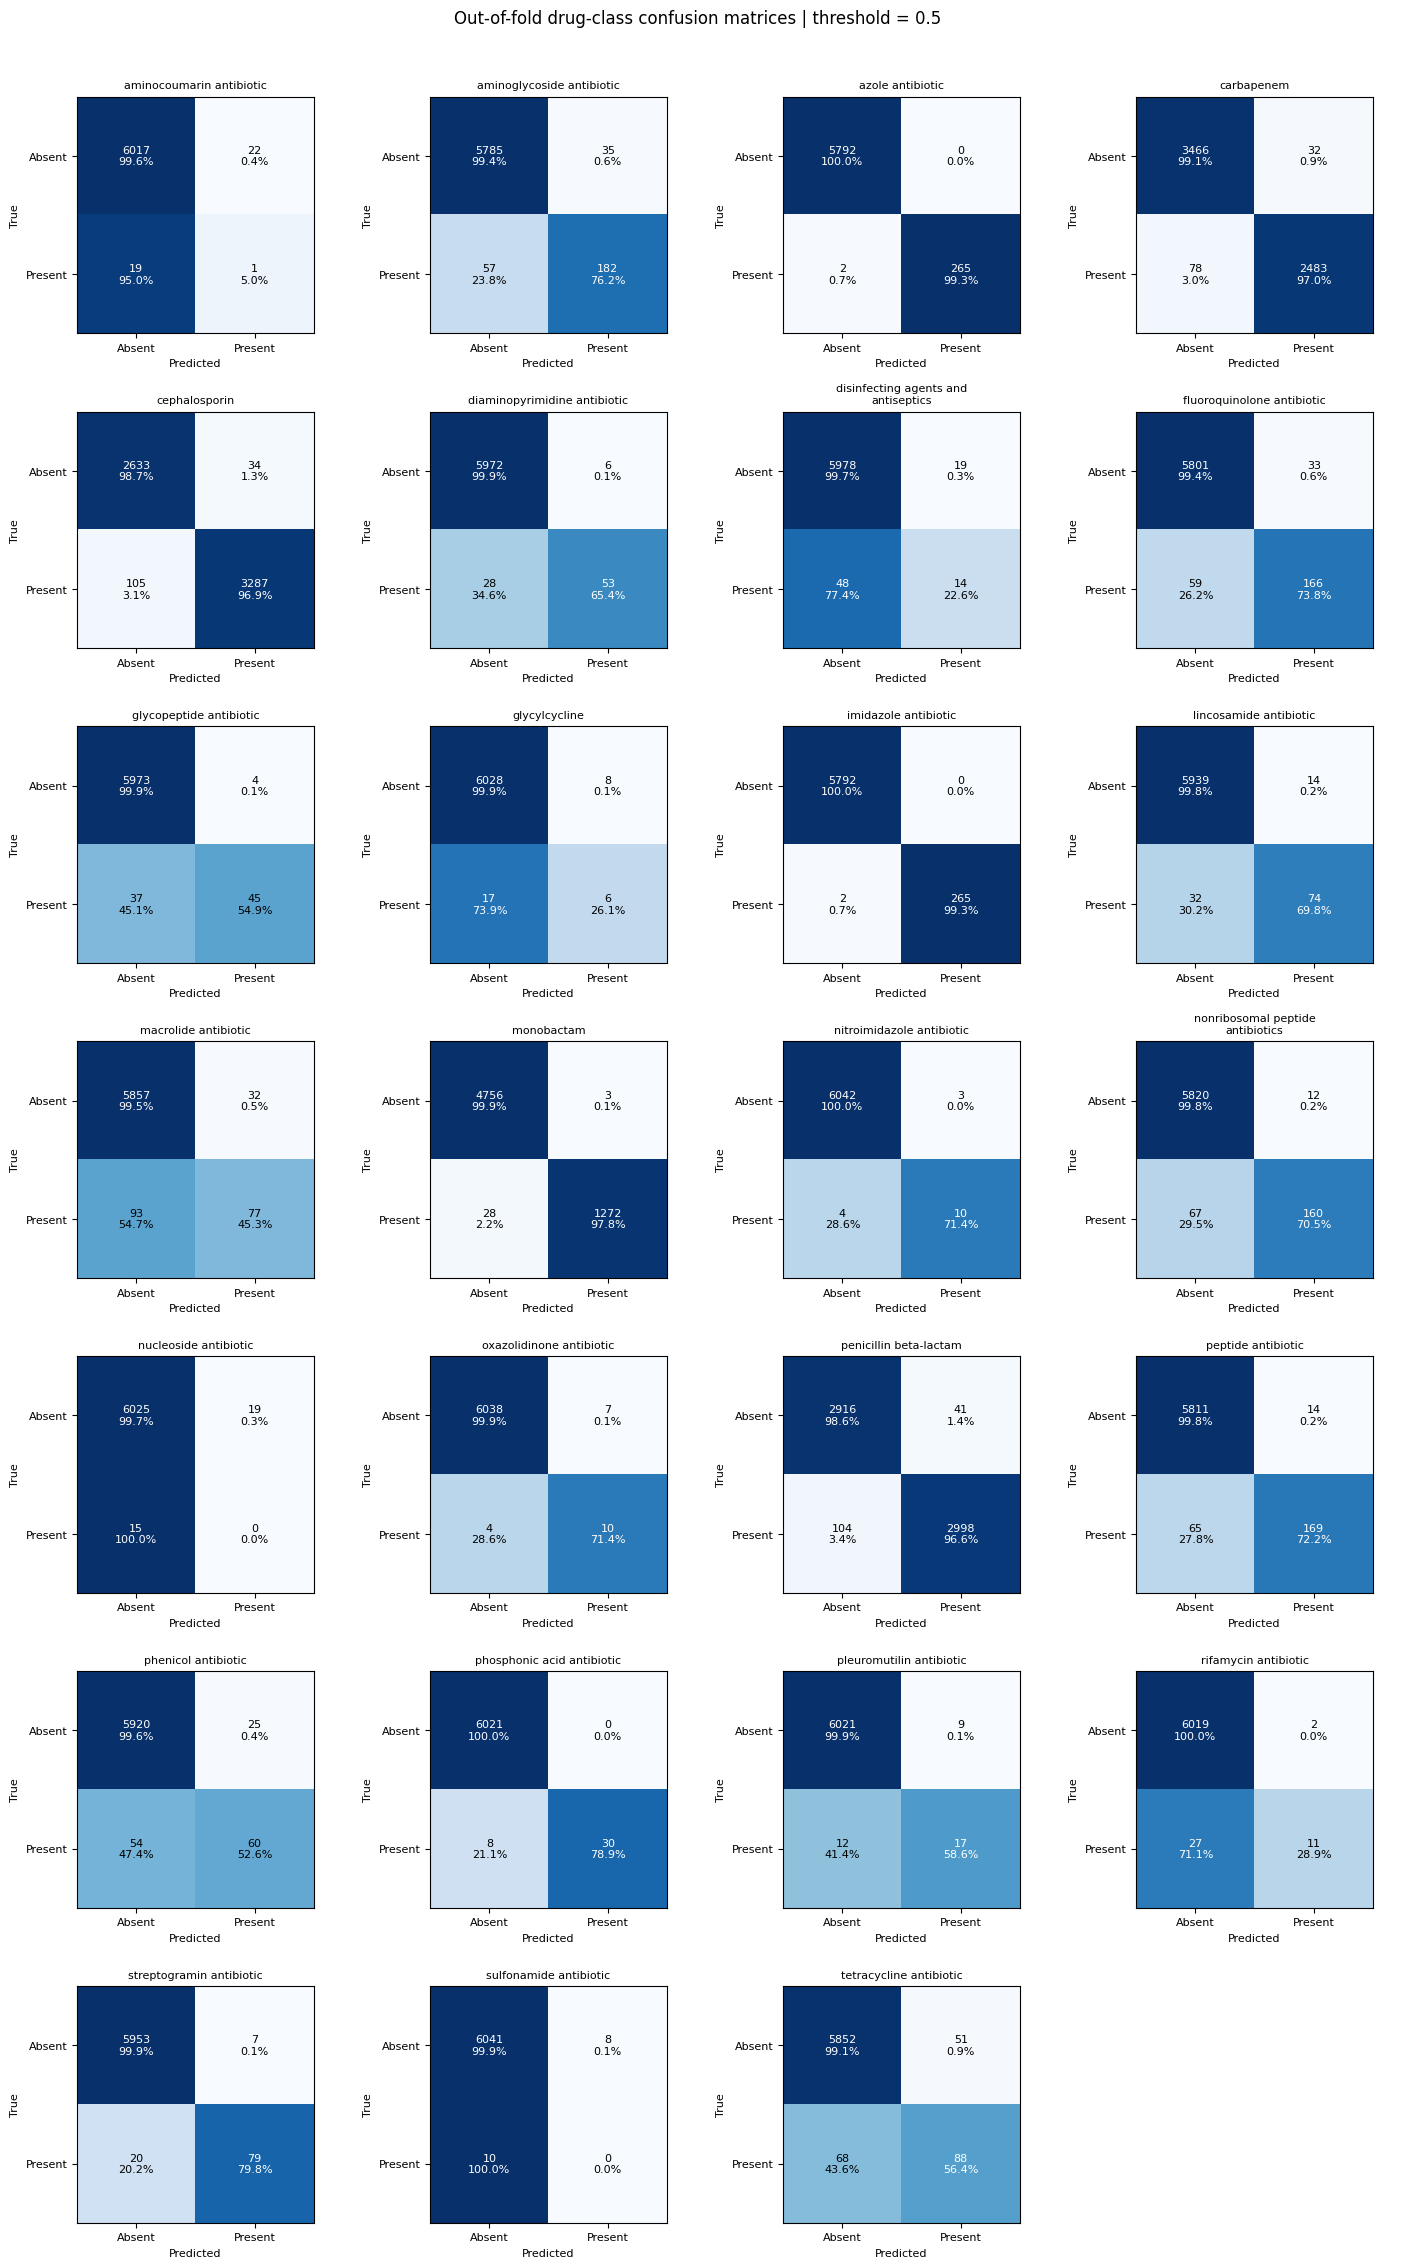

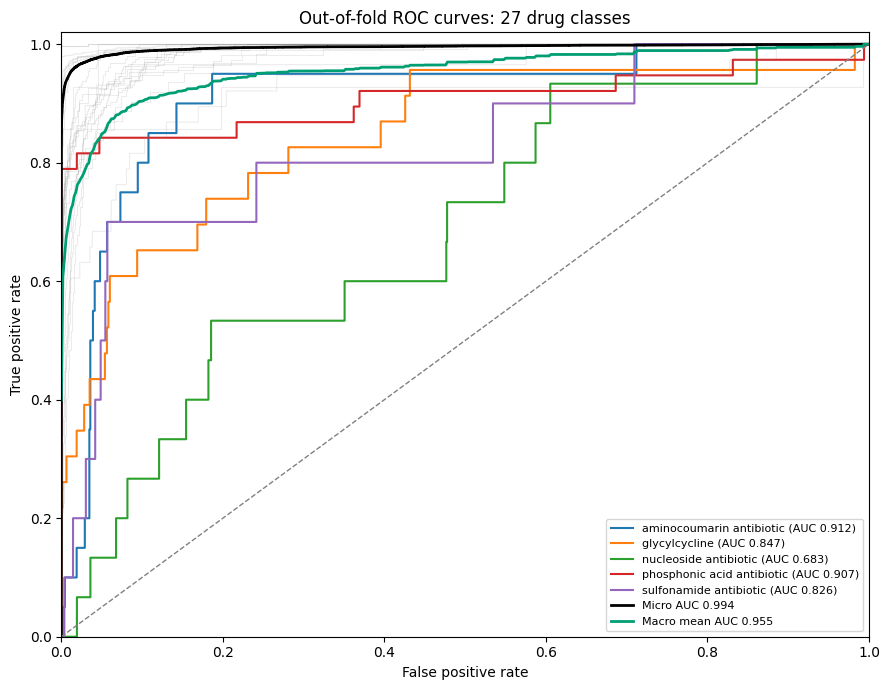

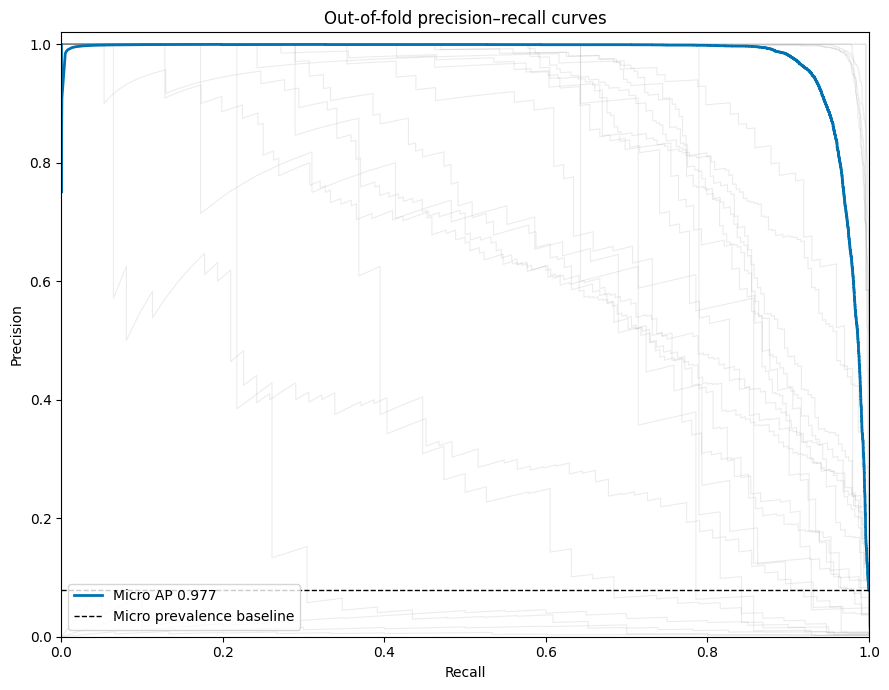

In [10]:
FIGURES_DIR = OUTPUT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def save_evaluation_figure(fig, stem):
    for suffix in ("png", "pdf"):
        fig.savefig(FIGURES_DIR / f"{stem}.{suffix}", dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

ncols = min(4, len(performance))
nrows = math.ceil(len(performance) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.3 * nrows), squeeze=False)
for ax, row in zip(axes.flat, performance.itertuples(index=False)):
    counts = np.array([[row.tn, row.fp], [row.fn, row.tp]], dtype=float)
    normalized = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(counts[i, j])}\n{normalized[i, j]:.1%}",
                    ha="center", va="center", fontsize=8,
                    color="white" if normalized[i, j] > 0.55 else "black")
    ax.set_title(textwrap.fill(row.drug_class, width=29), fontsize=8)
    ax.set_xticks([0, 1], ["Absent", "Present"], fontsize=8)
    ax.set_yticks([0, 1], ["Absent", "Present"], fontsize=8)
    ax.set_xlabel("Predicted", fontsize=8)
    ax.set_ylabel("True", fontsize=8)
for ax in list(axes.flat)[len(performance):]:
    ax.axis("off")
fig.suptitle(f"Out-of-fold drug-class confusion matrices | threshold = {eval_threshold:g}")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save_evaluation_figure(fig, "drug_class_confusion_matrices")

weakest = set(performance.nsmallest(min(5, len(performance)), "roc_auc")["drug_class"])
fig, ax = plt.subplots(figsize=(9, 7))
fpr_grid = np.linspace(0, 1, 501)
interpolated = []
for j, label in enumerate(eval_labels):
    fpr, tpr, _ = roc_curve(eval_y[:, j], eval_scores[:, j])
    interpolated.append(np.interp(fpr_grid, fpr, tpr))
    if label in weakest:
        auc = performance.set_index("drug_class").loc[label, "roc_auc"]
        ax.plot(fpr, tpr, lw=1.5, label=f"{label} (AUC {auc:.3f})")
    else:
        ax.plot(fpr, tpr, color="gray", alpha=0.15, lw=0.8)
micro_fpr, micro_tpr, _ = roc_curve(eval_y.ravel(), eval_scores.ravel())
ax.plot(micro_fpr, micro_tpr, color="black", lw=2, label=f"Micro AUC {summary['micro_roc_auc']:.3f}")
ax.plot(fpr_grid, np.mean(interpolated, axis=0), color="#009E73", lw=2,
        label=f"Macro mean AUC {summary['macro_roc_auc']:.3f}")
ax.plot([0, 1], [0, 1], "--", color="gray", lw=1)
ax.set(xlabel="False positive rate", ylabel="True positive rate",
       title=f"Out-of-fold ROC curves: {len(eval_labels)} drug classes", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
save_evaluation_figure(fig, "drug_class_roc_curves")

fig, ax = plt.subplots(figsize=(9, 7))
for j in range(len(eval_labels)):
    precision, recall, _ = precision_recall_curve(eval_y[:, j], eval_scores[:, j])
    ax.plot(recall, precision, color="gray", alpha=0.15, lw=0.8)
precision, recall, _ = precision_recall_curve(eval_y.ravel(), eval_scores.ravel())
ax.plot(recall, precision, color="#0072B2", lw=2,
        label=f"Micro AP {summary['micro_average_precision']:.3f}")
ax.axhline(eval_y.mean(), color="black", ls="--", lw=1, label="Micro prevalence baseline")
ax.set(xlabel="Recall", ylabel="Precision", title="Out-of-fold precision–recall curves",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
fig.tight_layout()
save_evaluation_figure(fig, "drug_class_precision_recall")


## 5. Full SHAP tables and the Max SHAP ≤ 2.0 filter

Match the calculation in `SHAP_FEATURE_IMPORTANCE.ipynb`. For drug class \(c\) and feature \(j\):

\[
I_{cj}=\frac{1}{N}\sum_{i=1}^{N}|\phi_{icj}|,\qquad
M_c=\max_j I_{cj},\qquad
\mathrm{pass}_c=[M_c\leq 2.0].
\]

Here \(\phi\) is a held-out raw-margin SHAP value and \(I\) is the exported `shap_importance`. **The threshold is a class-level gate on the maximum mean absolute feature importance**, not clipping individual SHAP values. This preserves the earlier rule: when any feature makes \(M_c>2.0\), the entire class's top-feature list is excluded from the filtered comparison table. Unfiltered values are always retained.

The supplied number 2.0 is a user-defined screening cutoff. Passing it does not establish statistical stability, and exceeding it does not prove overfitting. Raw-margin SHAP is not bounded by 2. The separate `max_abs_shap_sample` column records the largest absolute individual attribution and is **not** the quantity used by the legacy cutoff. No test, p-value or guaranteed confidence level follows from this filter.

Rank by mean absolute SHAP. Omit zero-importance entries from top-feature lists. The top-15 table retains the `feature` and `shap_importance` field names of the family results for comparison.


In [12]:
with np.load(OUTPUT_DIR / "drug_class_shap_cache.npz", allow_pickle=False) as cache:
    shap_labels = cache["labels"].tolist()
    shap_features = cache["feature_names"].tolist()
    shap_sources = cache["feature_source"].tolist()
    shap_means = cache["mean_abs"]
    shap_signed = cache["mean_signed"]
    shap_maxima = cache["max_abs"]
    shap_n = int(cache["n_explained"])

if not np.isfinite(shap_means).all() or (shap_means < 0).any():
    raise ValueError("Invalid mean absolute SHAP summary")
shap_rows = []
for j, label in enumerate(shap_labels):
    for k, feature in enumerate(shap_features):
        shap_rows.append({
            "drug_class": label, "feature": feature, "feature_source": shap_sources[k],
            "shap_importance": float(shap_means[j, k]),
            "mean_signed_shap": float(shap_signed[j, k]),
            "max_abs_shap_sample": float(shap_maxima[j, k]),
            "max_shap": float(shap_means[j].max()),
            "passes_safety_filter": bool(shap_means[j].max() <= SHAP_SAFETY_THRESHOLD),
            "safety_threshold": SHAP_SAFETY_THRESHOLD,
            "n_explained": shap_n, "shap_output": "raw_margin",
        })
shap_full = pd.DataFrame(shap_rows).sort_values(
    ["drug_class", "shap_importance", "feature"], ascending=[True, False, True]
).reset_index(drop=True)
shap_full["rank"] = shap_full.groupby("drug_class").cumcount() + 1
metric_table = pd.read_csv(OUTPUT_DIR / "drug_class_model_performance.csv")
shap_full = shap_full.merge(
    metric_table[["drug_class", "roc_auc", "average_precision", "f1"]],
    on="drug_class", how="left", validate="many_to_one",
)
safety_summary = shap_full[[
    "drug_class", "max_shap", "safety_threshold", "passes_safety_filter",
    "n_explained", "roc_auc", "average_precision", "f1",
]].drop_duplicates("drug_class")
top_shap = shap_full[(shap_full["rank"] <= TOP_N_FEATURES) & (shap_full["shap_importance"] > 0)].copy()
safe_top_shap = top_shap[top_shap["passes_safety_filter"]].copy()

shap_full.to_csv(OUTPUT_DIR / "drug_class_shap_importance_full.csv", index=False)
top_shap.to_csv(OUTPUT_DIR / "drug_class_top_features_shap.csv", index=False)
safe_top_shap.to_csv(OUTPUT_DIR / "drug_class_top_features_shap_safe.csv", index=False)
safety_summary.to_csv(OUTPUT_DIR / "drug_class_shap_safety_summary.csv", index=False)
shap_full.pivot(index="drug_class", columns="feature", values="shap_importance").reindex(
    columns=shap_features
).to_csv(OUTPUT_DIR / "drug_class_shap_profiles_full.csv")

print(f"{int(safety_summary['passes_safety_filter'].sum())}/{len(safety_summary)} classes pass Max SHAP <= {SHAP_SAFETY_THRESHOLD:g}")
display(safety_summary.sort_values("max_shap", ascending=False))
display(safe_top_shap[["drug_class", "rank", "feature", "feature_source", "shap_importance", "max_shap"]])


27/27 classes pass Max SHAP <= 2


,drug_class,max_shap,safety_threshold,passes_safety_filter,n_explained,roc_auc,average_precision,f1
12948,monobactam,1.393610,2.0,True,6059,0.997254,0.995459,0.987961
17928,penicillin beta-lactam,0.710174,2.0,True,6059,0.994281,0.995915,0.976388
2988,carbapenem,0.612696,2.0,True,6059,0.994877,0.994478,0.978329
6972,fluoroquinolone antibiotic,0.561069,2.0,True,6059,0.994109,0.901144,0.783019
25896,tetracycline antibiotic,0.529743,2.0,True,6059,0.984879,0.671657,0.596610
3984,cephalosporin,0.512666,2.0,True,6059,0.996242,0.997208,0.979294
16932,oxazolidinone antibiotic,0.487314,2.0,True,6059,0.995510,0.784927,0.645161
15936,nucleoside antibiotic,0.415940,2.0,True,6059,0.682958,0.005656,0.000000
996,aminoglycoside antibiotic,0.384086,2.0,True,6059,0.987888,0.868294,0.798246
14940,nonribosomal peptide antibiotics,0.382162,2.0,True,6059,0.986641,0.873171,0.802005


,drug_class,rank,feature,feature_source,shap_importance,max_shap
0,aminocoumarin antibiotic,1,DPC1_TF,Pfeature,0.168523,0.168523
1,aminocoumarin antibiotic,2,CTC_362,Pfeature,0.109031,0.168523
2,aminocoumarin antibiotic,3,M_aliphatic_index,ProFET,0.106828,0.168523
3,aminocoumarin antibiotic,4,DDR_H,Pfeature,0.100908,0.168523
4,aminocoumarin antibiotic,5,CTC_634,Pfeature,0.094722,0.168523
...,...,...,...,...,...,...
25906,tetracycline antibiotic,11,M_aliphatic_index,ProFET,0.140250,0.529743
25907,tetracycline antibiotic,12,DPC1_PE,Pfeature,0.120450,0.529743
25908,tetracycline antibiotic,13,DPC1_GI,Pfeature,0.119644,0.529743
25909,tetracycline antibiotic,14,DPC1_IP,Pfeature,0.118741,0.529743


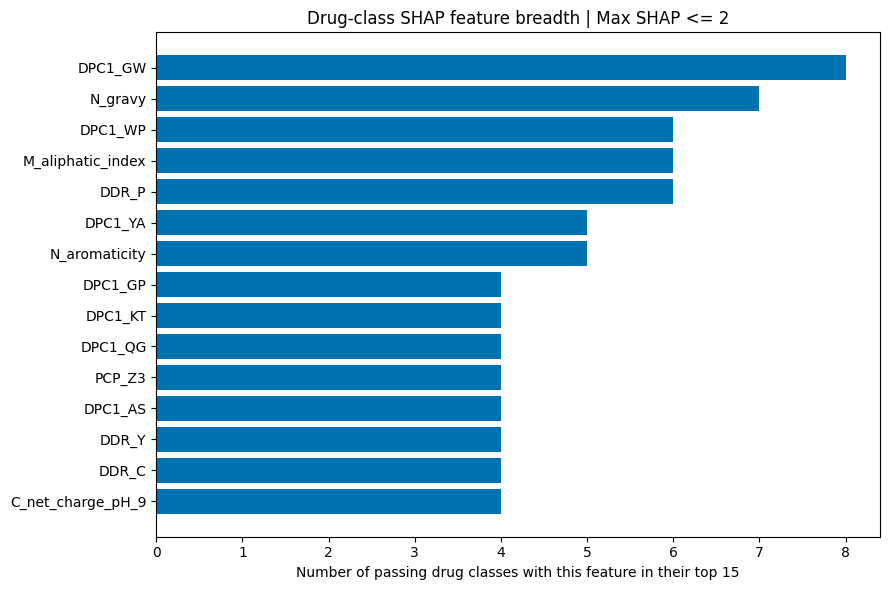

In [13]:
# Figure represents only top features from classes passing the requested filter.
fig, ax = plt.subplots(figsize=(9, 6))
if safe_top_shap.empty:
    ax.text(0.5, 0.5, "No positive-importance features passed the configured class-level filter",
            ha="center", va="center", wrap=True)
    ax.axis("off")
else:
    feature_breadth = safe_top_shap.groupby("feature").agg(
        n_classes=("drug_class", "nunique"), mean_importance=("shap_importance", "mean")
    ).sort_values(["n_classes", "mean_importance"], ascending=False).head(TOP_N_FEATURES)
    ax.barh(feature_breadth.index[::-1], feature_breadth["n_classes"].to_numpy()[::-1], color="#0072B2")
    ax.set_xlabel(f"Number of passing drug classes with this feature in their top {TOP_N_FEATURES}")
    ax.xaxis.get_major_locator().set_params(integer=True)
ax.set_title(f"Drug-class SHAP feature breadth | Max SHAP <= {SHAP_SAFETY_THRESHOLD:g}")
fig.tight_layout()
save_evaluation_figure(fig, "drug_class_top_shap_features_safe")


## 6. One saved model and reusable prediction helpers

The following helper cell is self-contained. In a fresh kernel, run this cell plus the unseen-sequence configuration/prediction cell below; the training sections are not needed for inference.

The archive contains native LightGBM model text and JSON metadata, including feature order, feature sources, supported/excluded labels and thresholds. No notebook-defined Python class or pickle/joblib object is needed to reload it. The predictions for different drug classes are independent scores and do **not** sum to one.

The reload check in the saving cell tests serialization only. It is not a generalization estimate. All reported classification metrics above come from CV-held-out proteins.


In [14]:
# Standalone helper cell: safe to run directly in a fresh prediction kernel.
import json
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import lightgbm as lgb


def load_drug_class_model(path):
    with zipfile.ZipFile(Path(path), "r") as archive:
        metadata = json.loads(archive.read("metadata.json").decode("utf-8"))
        if metadata.get("schema_version") != 1 or metadata.get("task") != "drug_class_multilabel":
            raise ValueError("Unsupported drug-class model archive")
        labels = metadata["labels"]
        features = metadata["feature_names"]
        files = metadata["model_files"]
        thresholds = np.asarray(metadata["thresholds"], dtype=float)
        if not labels or len(set(labels)) != len(labels) or len(set(features)) != len(features):
            raise ValueError("Invalid label/feature schema")
        if len(files) != len(labels) or thresholds.shape != (len(labels),):
            raise ValueError("Model/class/threshold count mismatch")
        if not np.isfinite(thresholds).all() or not ((thresholds > 0) & (thresholds < 1)).all():
            raise ValueError("Invalid saved decision thresholds")
        models = [
            lgb.Booster(model_str=archive.read(name).decode("utf-8"))
            for name in files
        ]
    if any(model.num_feature() != len(features) for model in models):
        raise ValueError("A saved model does not match the feature schema")
    return {"metadata": metadata, "models": models}


def prepare_drug_prediction_features(bundle, features):
    frame = pd.DataFrame([features]) if isinstance(features, (dict, pd.Series)) else pd.DataFrame(features).copy()
    order = bundle["metadata"]["feature_names"]
    if frame.empty or not frame.columns.is_unique:
        raise ValueError("Empty prediction input or duplicate columns")
    missing = [c for c in order if c not in frame.columns]
    if missing:
        raise ValueError(f"Missing {len(missing)} required descriptors, e.g. {missing[:10]}. Use both original extractors.")
    numeric = frame.loc[:, order].apply(pd.to_numeric, errors="raise").astype(float)
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    if numeric.isna().all(axis=1).any():
        raise ValueError("A query has no usable features")
    return numeric.to_numpy(dtype=float)


def predict_drug_class_scores(bundle, features):
    prepared = prepare_drug_prediction_features(bundle, features)
    scores = np.column_stack([
        model.predict(prepared, num_threads=2) for model in bundle["models"]
    ])
    if not np.isfinite(scores).all() or ((scores < 0) | (scores > 1)).any():
        raise ValueError("Invalid model scores")
    return scores


def read_unseen_feature_pair(pfeature_path, profet_path, bundle):
    metadata = bundle["metadata"]

    def read_one(path, source):
        frame = pd.read_csv(path, dtype={"sequence_id": str})
        required = [c for c in metadata["feature_names"] if metadata["feature_sources"][c] == source]
        missing = [c for c in required if c not in frame.columns]
        if "sequence_id" not in frame or missing:
            raise ValueError(f"{source} CSV needs sequence_id and the saved feature schema; missing descriptors: {missing[:10]}")
        if frame["sequence_id"].isna().any() or frame["sequence_id"].str.strip().eq("").any():
            raise ValueError(f"Missing sequence IDs in {path}")
        numeric = frame[required].apply(pd.to_numeric, errors="raise").astype(float)
        numeric = numeric.replace([np.inf, -np.inf], np.nan)
        # Group-labelled query exports can repeat a protein; require equal feature copies.
        counts = numeric.groupby(frame["sequence_id"]).nunique(dropna=False)
        if counts.gt(1).any().any():
            raise ValueError(f"Inconsistent duplicate query feature vectors in {path}")
        result = pd.concat([frame[["sequence_id"]], numeric], axis=1)
        return result.drop_duplicates("sequence_id")

    pf = read_one(pfeature_path, "Pfeature")
    pr = read_one(profet_path, "ProFET")
    merged = pf.merge(pr, on="sequence_id", how="outer", validate="one_to_one", indicator=True)
    if not merged["_merge"].eq("both").all():
        raise ValueError(f"Query Pfeature/ProFET IDs do not match: {merged['_merge'].value_counts().to_dict()}")
    return merged.drop(columns="_merge")


def drug_prediction_tables(bundle, features, sequence_ids):
    sequence_ids = list(sequence_ids)
    scores = predict_drug_class_scores(bundle, features)
    if len(sequence_ids) != len(scores) or len(sequence_ids) != len(set(sequence_ids)):
        raise ValueError("Query sequence IDs must be unique and match the feature rows")
    labels = bundle["metadata"]["labels"]
    thresholds = np.asarray(bundle["metadata"]["thresholds"])
    selected = scores >= thresholds[None, :]
    rows, score_rows = [], []
    for i, sequence_id in enumerate(sequence_ids):
        order = np.argsort(-scores[i], kind="stable")
        predicted = [labels[j] for j in order if selected[i, j]]
        top = int(order[0])
        rows.append({
            "sequence_id": sequence_id, "predicted_drug_classes": "; ".join(predicted),
            "n_predicted_classes": len(predicted),
            "prediction_status": "assigned" if predicted else "no_supported_class_above_threshold",
            "top_ranked_drug_class": labels[top], "top_ranked_score": float(scores[i, top]),
        })
        for j, label in enumerate(labels):
            score_rows.append({
                "sequence_id": sequence_id, "drug_class": label,
                "score": float(scores[i, j]), "threshold": float(thresholds[j]),
                "predicted_member": bool(selected[i, j]),
            })
    return pd.DataFrame(rows), pd.DataFrame(score_rows)


In [15]:
# Final refit on all available AROs, using the same design evaluated above.
# Writes ONE model archive; constituent native model texts stay inside it.
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
training_paths = {
    "pfeature_csv": PFEATURE_CSV, "profet_csv": PROFET_CSV,
    "aro_index_tsv": ARO_INDEX_TSV, "protein_fasta": PROTEIN_FASTA,
}
if SEQUENCE_CLUSTER_CSV is not None:
    training_paths["sequence_clusters"] = Path(SEQUENCE_CLUSTER_CSV)
model_metadata = {
    "schema_version": 1, "task": "drug_class_multilabel",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "labels": labels, "feature_names": feature_names, "feature_sources": feature_sources,
    "thresholds": [PREDICTION_THRESHOLD] * len(labels),
    "model_files": [f"models/class_{i:03d}.txt" for i in range(len(labels))],
    "model_params": LGB_PARAMS, "random_seed": RANDOM_SEED,
    "preprocessing": {"missing_values": "LightGBM_native_NaN", "excluded_prefixes": list(EXCLUDE_FEATURE_PREFIXES)},
    "n_training_aros": len(meta), "min_class_n": MIN_CLASS_N,
    "class_support": class_support.to_dict(orient="records"),
    "cv_grouping": grouping_source, "cv_group_radius": CV_GROUP_RADIUS,
    "n_cv_folds": len(folds), "package_versions": PACKAGE_VERSIONS,
    "training_inputs": {
        name: {"path": str(path), "sha256": file_sha256(path)}
        for name, path in training_paths.items()
    },
    "shap_output": "raw_margin", "shap_population": "all held-out AROs, row-weighted across shared CV folds",
    "shap_filter_definition": "max_feature(mean_rows(abs(raw_margin_SHAP))) <= threshold",
    "shap_safety_threshold": SHAP_SAFETY_THRESHOLD,
}
serialization_rows = min(16, len(X))
scores_before_save = np.empty((serialization_rows, len(labels)))
temporary_model = MODEL_PATH.with_name(MODEL_PATH.name + ".tmp")
with zipfile.ZipFile(temporary_model, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    archive.writestr("metadata.json", json.dumps(model_metadata, indent=2))
    for j, label in enumerate(labels):
        final_model = lgb.LGBMClassifier(random_state=RANDOM_SEED, **LGB_PARAMS)
        final_model.fit(X, Y[:, j])
        scores_before_save[:, j] = final_model.predict_proba(X[:serialization_rows])[:, 1]
        archive.writestr(model_metadata["model_files"][j], final_model.booster_.model_to_string())
        print(f"Final model {j + 1}/{len(labels)}: {label}", flush=True)

# Check the completed archive before replacing the final path.
reloaded_bundle = load_drug_class_model(temporary_model)
scores_after_reload = predict_drug_class_scores(reloaded_bundle, X_df.iloc[:serialization_rows])
np.testing.assert_allclose(scores_after_reload, scores_before_save, rtol=1e-10, atol=1e-10)
temporary_model.replace(MODEL_PATH)
print(f"Saved one drug-class model archive: {MODEL_PATH}")
print("Reload reproduces predictions. This verifies serialization, not unseen-sequence accuracy.")


Final model 1/27: aminocoumarin antibiotic
Final model 2/27: aminoglycoside antibiotic
Final model 3/27: azole antibiotic
Final model 4/27: carbapenem
Final model 5/27: cephalosporin
Final model 6/27: diaminopyrimidine antibiotic
Final model 7/27: disinfecting agents and antiseptics
Final model 8/27: fluoroquinolone antibiotic
Final model 9/27: glycopeptide antibiotic
Final model 10/27: glycylcycline
Final model 11/27: imidazole antibiotic
Final model 12/27: lincosamide antibiotic
Final model 13/27: macrolide antibiotic
Final model 14/27: monobactam
Final model 15/27: nitroimidazole antibiotic
Final model 16/27: nonribosomal peptide antibiotics
Final model 17/27: nucleoside antibiotic
Final model 18/27: oxazolidinone antibiotic
Final model 19/27: penicillin beta-lactam
Final model 20/27: peptide antibiotic
Final model 21/27: phenicol antibiotic
Final model 22/27: phosphonic acid antibiotic
Final model 23/27: pleuromutilin antibiotic
Final model 24/27: rifamycin antibiotic
Final model 2

## 7. Load the model and classify unseen proteins

First run the **same** Pfeature and ProFET extraction workflow on your new protein FASTA. This notebook consumes the resulting descriptors; it does not substitute an unrelated feature extractor or pretend that a training row is unseen.

In a fresh kernel run the standalone helper cell in Section 6, then the next cell after configuring:
- `NEW_PFEATURE_CSV`: Pfeature descriptors with `sequence_id`;
- `NEW_PROFET_CSV`: ProFET descriptors with exactly matching IDs.

Each file may contain one or many proteins. Class/family labels are not needed for prediction. Required feature columns must be present and are aligned to the saved order. Existing NaN values use the model's native missing-value handling; arbitrary missing columns are not silently filled with medians.

Output includes all classes exceeding their saved threshold and a separate ranked score table. An empty predicted set means no **supported** class passed the threshold; it does not prove absence of resistance or identify an excluded rare class.


In [16]:
# Fresh inference configuration: requires only the helper cell in Section 6.
from pathlib import Path
from IPython.display import display

MODEL_TO_LOAD = Path(
    "/home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/"
    "Final_Results/ML_on_Drug_Class/results/drug_class_classifiers/models/drug_class_classifier.zip"
)
NEW_PFEATURE_CSV = None  # Set to Path("/absolute/path/new_pfeature_features.csv")
NEW_PROFET_CSV = None    # Set to Path("/absolute/path/new_profet_features.csv")
PREDICTIONS_CSV = MODEL_TO_LOAD.parent.parent / "unseen_sequence_predictions.csv"
PREDICTION_SCORES_CSV = MODEL_TO_LOAD.parent.parent / "unseen_sequence_drug_class_scores.csv"

if NEW_PFEATURE_CSV is None and NEW_PROFET_CSV is None:
    print("Configure both new-sequence feature CSV paths to run prediction.")
elif NEW_PFEATURE_CSV is None or NEW_PROFET_CSV is None:
    raise ValueError("Both Pfeature and ProFET query CSVs are required")
else:
    unseen_model = load_drug_class_model(MODEL_TO_LOAD)
    unseen_features = read_unseen_feature_pair(NEW_PFEATURE_CSV, NEW_PROFET_CSV, unseen_model)
    unseen_predictions, unseen_scores = drug_prediction_tables(
        unseen_model, unseen_features, unseen_features["sequence_id"]
    )
    PREDICTIONS_CSV.parent.mkdir(parents=True, exist_ok=True)
    PREDICTION_SCORES_CSV.parent.mkdir(parents=True, exist_ok=True)
    unseen_predictions.to_csv(PREDICTIONS_CSV, index=False)
    unseen_scores.to_csv(PREDICTION_SCORES_CSV, index=False)
    display(unseen_predictions)
    print(f"Predictions: {PREDICTIONS_CSV}")
    print(f"All per-class scores: {PREDICTION_SCORES_CSV}")


Configure both new-sequence feature CSV paths to run prediction.


## 8. Prepare drug-class versus ARG-family feature comparisons

Read the existing family SHAP table; do not train a family classifier. Apply the same per-target `max(shap_importance) <= 2.0` gate **before** restricting the feature space. Keep raw values and exclusion information for auditing.

Exports:
- `comparison_top_features_safe.csv`: long table with target type/name, feature, source, mean absolute SHAP, rank and maximum SHAP.
- `comparison_top_feature_membership.csv`: target × feature 0/1 membership for future Jaccard comparisons, using reported positive-importance top-N lists projected onto the current drug model's feature schema.
- `comparison_shap_profiles.csv`: aligned numeric SHAP profiles for future correlation analysis; drug profiles contain every model feature.
- `comparison_profile_coverage.csv`: how much of each profile is available, how many top features survive projection, and whether the complete common profile is known.
- `comparison_safety_summary.csv`: all modelled targets' pass/fail status, including excluded targets.

The existing family file contains **only its top 15 features**. Unreported family values remain **NaN**, not zero. Complete-vector correlations require a full family × feature SHAP table; replace `FAMILY_SHAP_CSV` with that table when available. Do not call a correlation on a few overlapping reported features a full-profile correlation. For Jaccard, zero means “not in the reported top-N set,” not “measured importance is zero”; an empty union has undefined similarity and should be reported as missing.

Preserve original feature names. The new drug models exclude PRI/RRI descriptors while the family models used a different cleaning procedure and sample population. These are descriptive cross-model comparisons; SHAP scales and ranks also depend on the model, reference distribution, output space and correlations among descriptors. The same numerical cutoff does not remove those differences.


In [17]:
def normalize_shap_for_comparison(frame, label_column, target_type, safety_threshold, top_n):
    required = {label_column, "feature", "shap_importance"}
    if not required.issubset(frame.columns):
        raise ValueError(f"{target_type} SHAP table needs {sorted(required)}")
    result = frame[[label_column, "feature", "shap_importance"]].rename(columns={label_column: "label"}).copy()
    if result[["label", "feature"]].isna().any().any():
        raise ValueError("Missing target/feature names in a comparison table")
    result["shap_importance"] = pd.to_numeric(result["shap_importance"], errors="raise")
    if not np.isfinite(result["shap_importance"]).all() or result["shap_importance"].lt(0).any():
        raise ValueError("Comparison expects finite, non-negative mean absolute SHAP values")
    if result.duplicated(["label", "feature"]).any():
        raise ValueError("Duplicate target-feature entries in the supplied SHAP summary")
    result["target_type"] = target_type
    result["max_shap"] = result.groupby("label")["shap_importance"].transform("max")
    result["passes_safety_filter"] = result["max_shap"].le(safety_threshold)
    result = result.sort_values(["label", "shap_importance", "feature"], ascending=[True, False, True])
    result["rank"] = result.groupby("label").cumcount() + 1
    result["is_reported_top_feature"] = result["rank"].le(top_n) & result["shap_importance"].gt(0)
    return result


In [20]:
# Regenerate from saved CSVs: no model fitting or sequence classification in this section.
drug_summary = pd.read_csv(OUTPUT_DIR / "drug_class_shap_importance_full.csv")
with np.load(OUTPUT_DIR / "drug_class_shap_cache.npz", allow_pickle=False) as cache:
    comparison_features = cache["feature_names"].tolist()
    comparison_sources = dict(zip(cache["feature_names"].tolist(), cache["feature_source"].tolist()))

comparison_parts = [normalize_shap_for_comparison(
    drug_summary, "drug_class", "Drug class", SHAP_SAFETY_THRESHOLD, TOP_N_FEATURES
)]
family_loaded = FAMILY_SHAP_CSV is not None and Path(FAMILY_SHAP_CSV).is_file()
if family_loaded:
    comparison_parts.append(normalize_shap_for_comparison(
        pd.read_csv(FAMILY_SHAP_CSV), "family", "ARG family", SHAP_SAFETY_THRESHOLD, TOP_N_FEATURES
    ))
else:
    print(f"Family SHAP table not available at {FAMILY_SHAP_CSV}; exporting drug profiles only.")

comparison_all = pd.concat(comparison_parts, ignore_index=True)
comparison_all["in_drug_feature_schema"] = comparison_all["feature"].isin(comparison_features)
comparison_all["feature_source"] = comparison_all["feature"].map(comparison_sources).fillna("not_in_drug_schema")
comparison_safety = comparison_all[
    ["target_type", "label", "max_shap", "passes_safety_filter"]
].drop_duplicates(["target_type", "label"])
comparison_safety["safety_threshold"] = SHAP_SAFETY_THRESHOLD
comparison_safety.to_csv(OUTPUT_DIR / "comparison_safety_summary.csv", index=False)

passing = comparison_all[comparison_all["passes_safety_filter"]].copy()
reported_top = passing[passing["is_reported_top_feature"]].copy()
# The gate used every available feature before this projection.
shared_top = reported_top[reported_top["in_drug_feature_schema"]].copy()
shared_top.to_csv(OUTPUT_DIR / "comparison_top_features_safe.csv", index=False)
reported_top[~reported_top["in_drug_feature_schema"]].to_csv(
    OUTPUT_DIR / "comparison_top_features_outside_drug_schema.csv", index=False
)

profile_index = pd.MultiIndex.from_frame(
    passing[["target_type", "label"]].drop_duplicates().sort_values(["target_type", "label"])
)
if passing.empty:
    profiles = pd.DataFrame(index=profile_index, columns=comparison_features, dtype=float)
else:
    profiles = passing.pivot(
        index=["target_type", "label"], columns="feature", values="shap_importance"
    ).reindex(index=profile_index, columns=comparison_features)
# Important: no fillna(0) here. Unreported legacy-family importances are UNKNOWN.
profiles.to_csv(OUTPUT_DIR / "comparison_shap_profiles.csv")

membership = pd.DataFrame(0, index=profile_index, columns=comparison_features, dtype=np.uint8)
for row in shared_top.itertuples(index=False):
    membership.loc[(row.target_type, row.label), row.feature] = 1
membership.to_csv(OUTPUT_DIR / "comparison_top_feature_membership.csv")
coverage = profiles.notna().sum(axis=1).rename("n_known_feature_importances").to_frame()
coverage["n_features_in_comparison_schema"] = len(comparison_features)
coverage["complete_numeric_profile"] = coverage["n_known_feature_importances"].eq(len(comparison_features))
coverage["n_reported_top_features_in_schema"] = membership.sum(axis=1)
coverage["has_nonempty_top_feature_set"] = coverage["n_reported_top_features_in_schema"].gt(0)
coverage.reset_index().to_csv(OUTPUT_DIR / "comparison_profile_coverage.csv", index=False)
comparison_metadata = {
    "top_n": TOP_N_FEATURES, "safety_threshold": SHAP_SAFETY_THRESHOLD,
    "filter": "per-target maximum of mean absolute SHAP, inclusive cutoff; apply before feature projection",
    "feature_space": "current drug model schema; original descriptor names",
    "numeric_missing_policy": "NaN for unreported legacy-family importance; never infer zero",
    "membership_zero_means": "absent from supplied positive-importance top-N list within comparison schema",
    "empty_jaccard_union": "undefined; report missing",
    "family_source": str(FAMILY_SHAP_CSV) if family_loaded else None,
    "drug_source": str(OUTPUT_DIR / "drug_class_shap_importance_full.csv"),
    "comparison_limit": "different model populations/preprocessing; descriptive comparison only",
    "correlation_requirement": "complete comparable profiles; no full-vector correlation from a top-only family table",
}
(OUTPUT_DIR / "comparison_metadata.json").write_text(json.dumps(comparison_metadata, indent=2))
display(shared_top[["target_type", "label", "rank", "feature", "shap_importance", "max_shap"]].head(30))
display(coverage.reset_index())
print("Comparison tables saved. No correlation or Jaccard similarities have been calculated.")


Family SHAP table not available at /home/user/Pranjal-11-12-2025/ESKAPE_ARG_Family/CARD_DATA/card-data/refined_details/Final_Results/ML_on_Drug_Class/results/family_classifiers/top_features_shap.csv; exporting drug profiles only.


,target_type,label,rank,feature,shap_importance,max_shap
0,Drug class,aminocoumarin antibiotic,1,DPC1_TF,0.168523,0.168523
1,Drug class,aminocoumarin antibiotic,2,CTC_362,0.109031,0.168523
2,Drug class,aminocoumarin antibiotic,3,M_aliphatic_index,0.106828,0.168523
3,Drug class,aminocoumarin antibiotic,4,DDR_H,0.100908,0.168523
4,Drug class,aminocoumarin antibiotic,5,CTC_634,0.094722,0.168523
5,Drug class,aminocoumarin antibiotic,6,CTC_121,0.089548,0.168523
6,Drug class,aminocoumarin antibiotic,7,SER_K,0.084184,0.168523
7,Drug class,aminocoumarin antibiotic,8,DDR_W,0.083727,0.168523
8,Drug class,aminocoumarin antibiotic,9,SER_S,0.075198,0.168523
9,Drug class,aminocoumarin antibiotic,10,CTC_216,0.071491,0.168523


,target_type,label,n_known_feature_importances,n_features_in_comparison_schema,complete_numeric_profile,n_reported_top_features_in_schema,has_nonempty_top_feature_set
0,Drug class,aminocoumarin antibiotic,996,996,True,15,True
1,Drug class,aminoglycoside antibiotic,996,996,True,15,True
2,Drug class,azole antibiotic,996,996,True,15,True
3,Drug class,carbapenem,996,996,True,15,True
4,Drug class,cephalosporin,996,996,True,15,True
5,Drug class,diaminopyrimidine antibiotic,996,996,True,15,True
6,Drug class,disinfecting agents and antiseptics,996,996,True,15,True
7,Drug class,fluoroquinolone antibiotic,996,996,True,15,True
8,Drug class,glycopeptide antibiotic,996,996,True,15,True
9,Drug class,glycylcycline,996,996,True,15,True


Comparison tables saved. No correlation or Jaccard similarities have been calculated.


## Output guide and interpretation

All paths are under `OUTPUT_DIR`, except explicitly configured query outputs.

| Output | Purpose |
|---|---|
| `drug_class_support_and_exclusions.csv`, `fold_class_support.csv` | Represented/eligible classes and fold support |
| `sequence_fold_manifest.csv` | ARO provenance, exact sequence hashes, group and validation-fold assignments |
| `drug_class_model_performance.csv`, `drug_class_cv_summary.json` | Held-out per-class and multi-label performance |
| `drug_class_oof_cache.npz`, `drug_class_oof_scores.csv` | Reusable held-out scores with IDs |
| `figures/` | Confusion-matrix grid, ROC, precision–recall and filtered SHAP feature plots |
| `drug_class_shap_importance_full.csv`, `fold_shap_importance.csv` | Full feature importances and fold summaries |
| `drug_class_top_features_shap_safe.csv`, `drug_class_shap_safety_summary.csv` | Requested top-feature table and the Max SHAP gate |
| `models/drug_class_classifier.zip` | Single loadable multi-label model archive with native predictors and metadata |
| `unseen_sequence_predictions.csv`, `unseen_sequence_drug_class_scores.csv` | Membership predictions and complete score table for user-supplied queries |
| `comparison_*.csv`, `comparison_metadata.json` | Aligned family/drug-class tables and explicit coverage/missingness |

The notebook reports results only after execution. It contains no copied numerical performance claims from the ARG-family run. Strong CV performance with descriptor-based grouping remains an internal estimate; independent sequence-cluster or external-data evaluation is needed for claims about novel homologues. Excluded rare labels are outside the saved model's prediction vocabulary.

The safety cutoff filters explanation tables only; it does not remove predictors from the saved classifier or change classification metrics.

## Method and software references

- SHAP output scale, reference choice and additivity checks: [TreeExplainer documentation](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).
- Binary LightGBM settings and class-weighting caveats: [LGBMClassifier documentation](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html).
- Several labels per sample: [scikit-learn multi-label classification](https://scikit-learn.org/stable/modules/multiclass.html).
- Training/validation separation and grouped evaluation: [scikit-learn cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).
- Kassis, T., Agarwal, V., He, Y., Patel, D., & Brueckner, A. M. (2026). *Scientific Agent Skills: A Library of Procedural Knowledge for Research Agents*. [arXiv:2609.00065](https://doi.org/10.48550/arXiv.2609.00065). Project scikit-learn and SHAP guidance informed this notebook.
